In [1]:
!rm -rf DL_Data_sets/
!git clone --branch images https://github.com/octavio-navarro/DL_Data_sets.git


Cloning into 'DL_Data_sets'...
remote: Enumerating objects: 64973, done.
remote: Counting objects: 100% (504/504), done.
remote: Compressing objects: 100% (493/493), done.
remote: Total 64973 (delta 15), reused 497 (delta 11), pack-reused 64469 (from 1)
Receiving objects: 100% (64973/64973), 1.54 GiB | 4.33 MiB/s, done.
Resolving deltas: 100% (138/138), done.


# Computer vision

The goal of computer vision is to understand the story unfolding in a picture. As humans, this is quite simple. But for computers, the task is extremely difficult.

Computer vision is a field that enables machines to interpret and understand the visual world. By using algorithms and models, computer vision allows computers to automatically process, analyze, and derive meaningful insights from images, videos, and other visual inputs. The goal is to replicate human vision capabilities, allowing computers to identify and interpret visual objects, scenes, and activities.

![Applications_1](https://cdn.prod.website-files.com/614c82ed388d53640613982e/6475f0e3ba6ef9bc2836272b_image%20classification%20classification%20localization%20detection.webp)

![Applications_2](https://images.prismic.io/encord/687a497d-e323-4772-8cd4-4bd67b9dd9a5_image7.png?auto=compress,format)

There are now many vision systems in routine industrial use: cameras inspect mechanical parts to check size, food is inspected for quality and images used in as- tronomy benefit from computer vision techniques. Forensic studies and biometrics (ways to recognise people) using computer vision include automatic face recognition.

There are many different image sources. In medical studies, MRI is good for imaging soft tissue but does not reveal the bone structure; this can be achieved by using computerised tomography which is better at imaging bone, as opposed to soft tissue. Remotely sensed images can be derived from infrared (thermal) sensors or synthetic-aperture radar, rather than by cameras. Spatial information can be provided by two-dimensional arrays of sensors, including sonar arrays. There are perhaps more varieties of sources of spatial data in medical studies than in any other area. But computer vision techniques are used to analyse any form of data, not just the images from cameras.

![MRI](https://case.edu/med/neurology/NR/mri%20slices%20new.jpg)

[![Computer vision](https://img.youtube.com/vi/OnTgbN3uXvw/0.jpg)](https://www.youtube.com/watch?v=OnTgbN3uXvw)

## Applications of Computer Vision:

1. Autonomous Vehicles:

Computer vision is crucial for self-driving cars, enabling them to recognize and respond to road signs, pedestrians, other vehicles, and obstacles. Real-time object detection and tracking are key for safe navigation.

2. Medical Imaging:

In healthcare, computer vision is used for tasks like diagnosing diseases from medical images (e.g., X-rays, MRIs) and detecting abnormalities like tumors or fractures, helping doctors make quicker and more accurate diagnoses.

3. Retail and E-commerce:

Computer vision powers visual search and product recognition in online shopping platforms, allowing users to search for products based on images. It is also used in customer behavior analysis and inventory management in stores.

4. Robotics:

Vision-guided robots can recognize and manipulate objects, navigate through environments, and interact with humans. This is critical for applications in manufacturing, logistics, and personal assistance.

5. Agriculture:

Computer vision helps in monitoring crops, detecting plant diseases, analyzing soil health, and even guiding autonomous farm equipment to perform tasks like harvesting.

6. Cybersecurity:

Computer vision enhances cybersecurity by enabling real-time threat detection, improving biometric security with facial recognition, and identifying phishing and malware through visual analysis. It helps detect deepfakes, prevents visual hacking, and secures IoT devices from tampering. Integrated with AI, it provides adaptive and proactive defenses.






# Computer vision pipeline

A computer vision pipeline is a series of steps that most computer vision applications will go through. Many vision applications start off by acquiring images and data, then processing that data, performing some analysis and recognition steps, then finally performing an action. The general pipeline and a specific example of a pipeline applied to facial expression recognition is pictured below.

![](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/face_recognition_pipeline.png)

### Standardizing Data

Pre-processing images is all about standardizing input images so that you can move further along the pipeline and analyze images in the same way. In machine learning tasks, the pre-processing step is often one of the most important. For example, for a traffic sign classification task:

If the images are different sizes, or even cropped differently, then this counting tactic will likely fail. So, it's important to pre-process these images so that they are standardized before they move along the pipeline. In the example below, you can see that the images are pre-processed into a standard square size.

The algorithm counts up the number of red pixels in a given image and if there are enough of them, it classifies an image as a stop sign. In this example, we are just extracting a color feature and skipping over selecting an area of interest (we are looking at the whole image). In practice, you'll often see a classification pipeline that looks like this:

![Correct Traffic classification](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/traffic_sign_classification_2.png)

# Images as Grids of Pixels

Every image consists of a set of pixels. Pixels are the raw building blocks of an image. Normally, we think of a pixel as the “color” or the “intensity” of light that appears in a given place in our image.

If we think of an image as a grid, each square in the grid contains a single pixel.

For example, let’s pretend we have an image with a resolution of 500 × 300. This means that our image is repre-sented as a grid of pixels, with 500 rows and 300 columns. Overall, there are 500 × 300 = 150, 000 pixels in our image.

Most pixels are represented in two ways: grayscale and color. In a grayscale image, each pixel has a value between 0 and 255, where zero corresponds to “black” and 255 corresponds to “white”. The values in between 0 and 255 are varying shades of gray, where values closer to 0 are darker and values closer to 255 are lighter.

Color pixels are normally represented in the RGB color space – one value for the Red component, one for Green, and one for Blue. Other color spaces exist, but let’s start with the basics and move our way up from there.

Each of the three colors is represented by an integer in the range 0 to 255, which indicates how “much” of the color there is. Given that the pixel value only needs to be in the range [0, 255], we normally use an 8-bit unsigned integer to represent each color intensity.

We then combine these values into an RGB tuple in the form (red, green, blue). This tuple represents our color. To construct a white color, we would fill up each of the red, green, and blue buckets completely, like this: (255, 255,255). Then, to create a black color, we would empty each of the buckets out: (0,0,0). To create a pure red color, we would fill up the red bucket (and only the red bucket) up completely: (255,0,0)

### Import resources

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import PIL
from PIL import Image, ImageFilter  # PIL: the imaging library of this course

%matplotlib inline


### Read in and display the image

It's worth getting the channel order straight from the start: PIL reads images in RGB order (Red, Green, Blue), the same order we normally think in and the order used by matplotlib. (OpenCV, the other major computer-vision library, stores channels in BGR order and would have to be converted before displaying — with PIL there is nothing to convert.)


Image dimensions: (427, 640, 3)


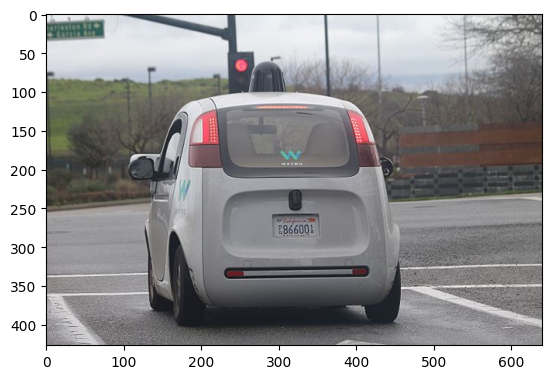

In [3]:
# Read in the image
image = Image.open('DL_Data_sets/images/waymo_car.jpg')

# Convert to a NumPy array to inspect the pixels -> mandatory for matplotlib visualization
image_rgb = np.array(image)

# Print out the image dimensions
print('Image dimensions:', image_rgb.shape)

plt.imshow(image_rgb)


(427, 640)


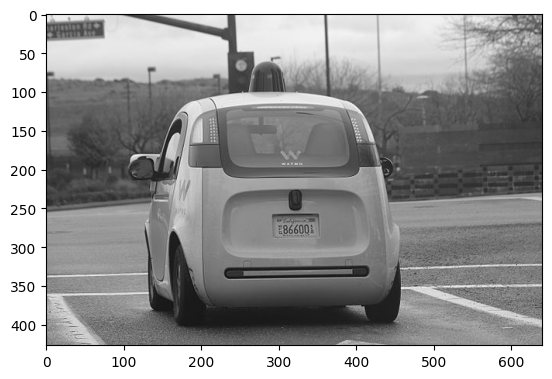

In [4]:
# Change from color to grayscale (PIL mode 'L' = 8-bit luminance)
gray_image = np.array(image.convert('L'))

print(gray_image.shape)
plt.imshow(gray_image, cmap='gray')


We convert PIL images into NumPy arrays to inspect them numerically. Conceptually, we can think of this representation as a matrix. In order to access a pixel value, we just need to supply the x and y coordinates of the pixel we are interested in.


In [21]:
# Print specific grayscale pixel values
x = 400
y = 300

print("Color image values: Pixels are represented as a tuple")
print(image_rgb[y,x])
print(image_rgb[0][0:10]) # -> primeros 10 pixeles de la primera fila
print(image_rgb[0, 0:10]) # -> primeros 10 pixeles de la primera fila

print("\nGrayscale Image values: Pixels are represented as integers")
print(gray_image[y,x])
print(gray_image[0][0:10]) # -> primeros 10 pixeles de la primera fila
print(gray_image[0, 0:10]) # -> primeros 10 pixeles de la primera fila

'''en la posición 300,400, el pixel de la imagen en color tiene un valor de (0, 0, 0) que representa el color negro, mientras que el pixel correspondiente en la imagen en escala de grises tiene un valor de 0, que también representa el color negro. Esto indica que ambos píxeles son oscuros y no contienen información de color.'''


Color image values: Pixels are represented as a tuple
[159 158 163]
[[237 237 239]
 [235 235 237]
 [236 236 238]
 [240 240 242]
 [238 238 240]
 [222 222 224]
 [191 191 193]
 [166 166 168]
 [219 219 221]
 [240 240 242]]
[[237 237 239]
 [235 235 237]
 [236 236 238]
 [240 240 242]
 [238 238 240]
 [222 222 224]
 [191 191 193]
 [166 166 168]
 [219 219 221]
 [240 240 242]]

Grayscale Image values: Pixels are represented as integers
159
[237 235 236 240 238 222 191 166 219 240]
[237 235 236 240 238 222 191 166 219 240]


'en la posición 300,400, el pixel de la imagen en color tiene un valor de (0, 0, 0) que representa el color negro, mientras que el pixel correspondiente en la imagen en escala de grises tiene un valor de 0, que también representa el color negro. Esto indica que ambos píxeles son oscuros y no contienen información de color.'

In [22]:
#Find the maximum and minimum grayscale values in this image

max_val = np.amax(gray_image) # valor max en toda la matriz
min_val = np.amin(gray_image) # valor min en toda la matriz

print('Max: ', max_val)
print('Min: ', min_val)

# esto eventualmente lo vamos a normalizar para que entre al tensor


Max:  255
Min:  2


[[140 140 140 ... 125 124 124]
 [141 141 141 ... 125 125 125]
 [142 142 141 ... 126 126 125]
 ...
 [143 143 142 ... 133 134 134]
 [145 145 144 ... 136 136 136]
 [147 146 146 ... 139 139 139]]


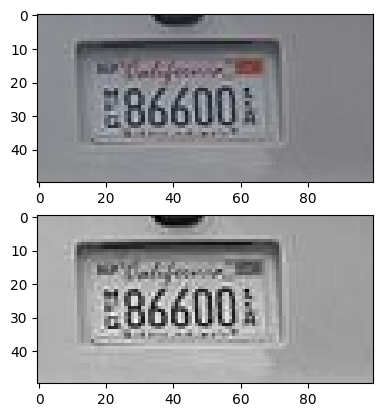

In [7]:
# Display a specific part of the image

sub_image = gray_image[250:300, 280:380]
print(sub_image)

f, (color_ax, gray_ax) = plt.subplots(2, 1)

gray_ax.imshow(sub_image, cmap='gray')
color_ax.imshow(image_rgb[250:300, 280:380])


We can use array slices to change the color of a region of pixels. We will set a the region of the top left square to have a value of (0, 255, 0) (green).



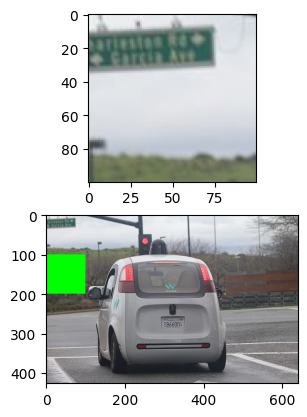

In [8]:
image_replace = image_rgb.copy()

f, (corner_ax, image_replace_ax) = plt.subplots(2, 1)

top_corner = image_replace[0:100, 0:100]
corner_ax.imshow(top_corner)

image_replace[100:200, 0:100] = (0, 255, 0) # de toda esa area cambiarlos a verde

image_replace_ax.imshow(image_replace)


### Images from numpy arrays

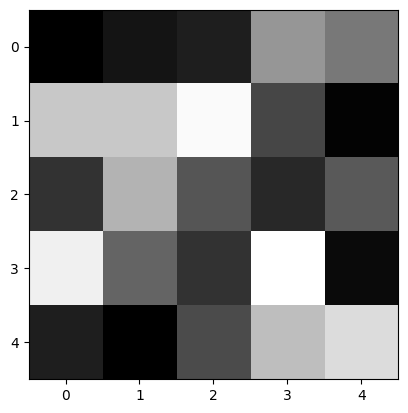

In [9]:
# Create a 5x5 image using just grayscale, numerical values
tiny_image = np.array([[0, 20, 30, 150, 120],
                      [200, 200, 250, 70, 3],
                      [50, 180, 85, 40, 90],
                      [240, 100, 50, 255, 10],
                      [30, 0, 75, 190, 220]])

plt.imshow(tiny_image, cmap='gray')

# Challenge

Modify the following cell to produce the following image:

![Gradient](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/gradient.png)

[[255   0   0]
 [255   0   0]
 [255   0   0]
 [255   0   0]
 [255   0   0]]


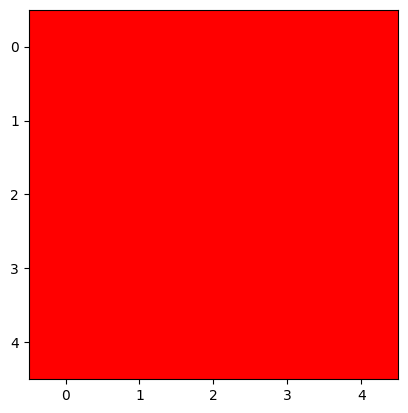

In [24]:
# This code displays an image where all the pixels are red. Modify it so that the pixels create a gradient to white.
gradient_size = 5
gradient = np.zeros((gradient_size, gradient_size, 3), dtype=np.uint8)

for x in range(gradient.shape[0]):
    for y in range(gradient.shape[1]):
        gradient[y, x] = (255, 0, 0)
print(gradient[-1])
plt.imshow(gradient)


---


[[255  42  42]
 [255  95  95]
 [255 148 148]
 [255 201 201]
 [255 255 255]]


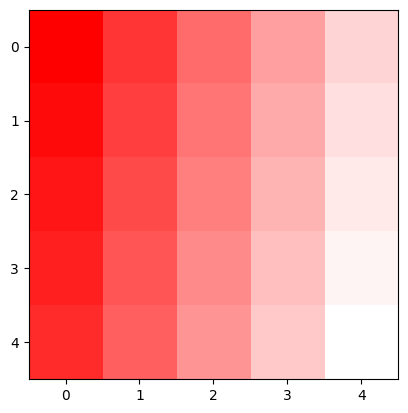

In [119]:
# gradient to white using slicers, each line loses some red and gains some green and blue, until white is reached
# This code displays an image where all the pixels are red. Modify it so that the pixels create a gradient to white.
gradient_size = 5
gradient = np.zeros((gradient_size, gradient_size, 3), dtype=np.uint8)
g = 0
g_change = 255/24
'''
tiny image code 
tiny_image = np.array([[0, 20, 30, 150, 120],
                      [200, 200, 250, 70, 3],
                      [50, 180, 85, 40, 90],
                      [240, 100, 50, 255, 10],
                      [30, 0, 75, 190, 220]])
'''
for x in range(gradient.shape[0]):
    for y in range(gradient.shape[1]):
            gradient[y,x] = (255, g, g)
            g += g_change
print(gradient[-1])
plt.imshow(gradient)

# Filters

In image processing and computer vision, noise refers to any unwanted or random variations of pixel intensity in an image that obscure the true visual information. Noise typically originates from various sources, such as environmental conditions, sensor limitations, or transmission errors, and can significantly degrade the quality of an image. We normally use filters to try to remove noise.

Filters are algorithms or techniques applied to images to enhance or modify their visual properties. They are often used for tasks like noise reduction, edge detection, blurring, sharpening, and feature extraction. They operate by manipulating the pixel values of the image based on a specific rule or mathematical operation.

Basically, they filter out unwanted or irrelevant information in an image, or to amplify features like object boundaries or other distinguishing traits.


## Frequency in images

Frequency in images is a rate of change: the rate at which pixel intensity values change across an image. Just like in audio signals, where frequency indicates how rapidly sound waves oscillate, in images, frequency describes the variation of pixel intensities, such as edges, textures, and smooth regions. The concept of frequency is essential for understanding how an image can be broken down into its high-frequency and low-frequency components.

1. Low-Frequency Components:

- These correspond to slow or gradual changes in pixel intensity, such as smooth gradients or large uniform areas. For instance, a clear sky or a solid-colored object in an image contains low-frequency information because there is little variation in color or intensity over large areas.
- A low-frequency image may be one that is relatively uniform in brightness or changes very slowly.
- Low-frequency details usually represent the general structure and basic forms in the image.

2. High-Frequency Components:

- These refer to rapid changes in pixel intensity, such as sharp edges, fine textures, and small details. For example, the boundary between two distinct objects or fine-grained textures in a fabric represent high-frequency information.
- A high-frequency image is one where the intensity changes a lot, and the level of brightness changes quickly from one pixel to the next.
- High-frequency details are critical for identifying edges and sharp features in the image.

![High and low frequency images](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/high-low_frequency.png)

## Convolution

Convolution is a powerful and widely used technique in image processing
and other areas of science. We start by defining the convolution of two functions f(x) and g(x) as the integral:

$f(x) \ast g(x) = \int_{-\inf}^{\inf} f(u) g(x-u) du$

The action of this integral is normally described as the result of applying a point spread function $g(x)$ to all points of a function $f(x)$ and accumulating the contributions at every point.

When convolution is applied to digital images, the above formulation changes
in two ways:

1. a double integral must be used in respect of the two dimensions
2. integration must be changed into discrete summation

The new form of the convolution is:

$ F(x, y) = \sum_i \sum_j f(x+i, y+j) h(i, j)$

which involves multiplying corresponding values in the modified mask and the neighborhood under consideration. Re-expressing this result for a 3 x 3 neighborhood
and writing the mask coefficients in the form:

$
\begin{bmatrix}
h1 & h2 & h4 \\
h4 & h5 & h6 \\
h7 & h8 & h9 \\
\end{bmatrix}
$

the algorithm can be obtained in terms of our earlier notation:

```
for all pixels in image do {
Q0 = P0 * h0 + P1 * h1 + P2 * h2 + P3 * h3 + P4 * h4 + P5 * h5 + P6 * h6 + P7 * h7 + P8 * h8;
}
```


## Convolution Kernels

A kernel is a matrix of numbers that modifies and image. An example of an edge detection filter is the laplacian:


$\begin{pmatrix} 0&-1&0\\ -1&4&-1 \\ 0&-1&0 \end{pmatrix}$

PRIORIZA EL 4, MANDA A 0 CUANDO MULTIPLEQUEMOS CON LOS FILTROS. tRATAR QUE LOS FILTROS ESTEN EN 0, PARA NO PASARME DEL RANGO DE LA IMAGEN

It is a three by three kernel whose elements all sum to zero. It is important that these kernels sum to zero, because they calculate the differente or change between neighboring pixels.

Differences are calculated by substracting pixel values from one another. In this case, substracting the value of the pixels that surround a center pixel. To apply this kernel, an image is convolved with this kernel.

A convolution is performed by taking a kernel and passing it over an image pixel by pixel, transforming it based on these numbers.

![Convolution](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/Convolution.png)

## High-Pass Filters

High pass filters are used to make an image appear sharper and enchance high-frequency parts of an image: neighboring pixels rapidly change, like from very dark to very light pixels. Since these are patterns of intensity, the these filters will operate on grayscale images that represent this information and display patterns of lightness and darkness in a simple format.

In areas where a pixel is way brighter than its immediate neighbors, the high-pass filter will enhance that change and create a line. This emphasizes edges, which are areas in an image where the intensity changes very quickly, and often indicate object boundaries.

![Lena](https://raw.githubusercontent.com/octavio-navarro/Computer-Vision/main/Notebooks/images/lena_edges.png)

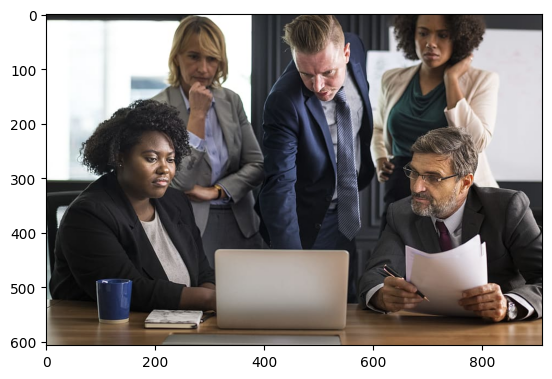

In [11]:
# Read in the image
image_people = Image.open('DL_Data_sets/images/business_people.jpg')

plt.imshow(image_people)


### Convert the image to grayscale

(607, 910)


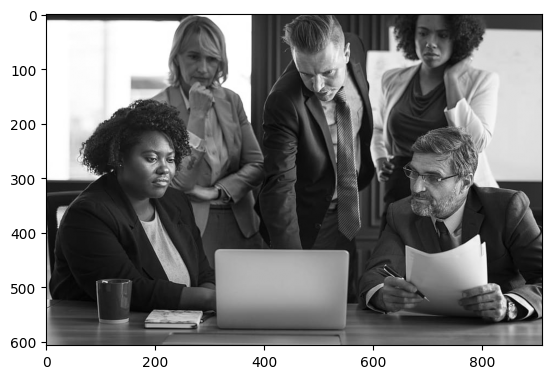

In [102]:
# Convert to grayscale for filtering
gray_people = image_people.convert('L')

plt.imshow(gray_people, cmap='gray')

print(np.array(gray_people).shape)

# turn to img
gray_people = np.array(gray_people)


### Challenge: Create and apply a custom kernel

Implement your own filtered image by applying the [Sobel](https://en.wikipedia.org/wiki/Sobel_operator) operators to the image.

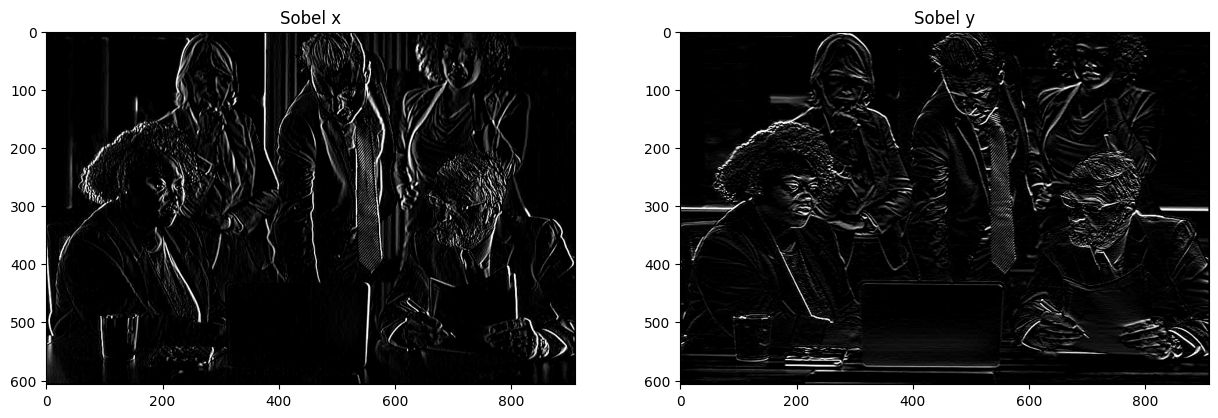

In [116]:
# Create a custom kernel
'''
Creating a custom kernel for edge detection using the Sobel operator. The Sobel operator is used to find the gradient of the image intensity at each pixel, which can be used to detect edges in the image. The Sobel operator consists of two 3x3 convolution kernels, one for detecting changes in the horizontal direction (sobel_x) and one for detecting changes in the vertical direction (sobel_y).
'''
# 3x3 array for edge detection
sobel_y = np.array([
                    [ 1, 2, 1],
                    [ 0, 0, 0],
                    [ -1, -2, -1]
                    ])

sobel_x = np.array([
                    [ 1, 0, -1],
                    [ 2, 0, -2],
                    [ 1, 0, -1]])

# Get the shape of the image
y_limit, x_limit = np.array(gray_people).shape 

filtered_people_x_custom = np.zeros((y_limit, x_limit), dtype=np.uint8)  # fill in the filtered image in the challenge below
filtered_people_y_custom = np.zeros((y_limit, x_limit), dtype=np.uint8)  # fill in the filtered image in the challenge below

# Challenge: loop over the pixels of gray_people and apply sobel_x / sobel_y
# to fill in filtered_people_x_custom and filtered_people_y_custom

for y in range(1, y_limit-1):
    for x in range(1, x_limit-1):
        # Get the 3x3 region of interest
        region = np.array(gray_people)[y-1:y+2, x-1:x+2] # y-1:y+2 pixel de arriba y abajo, x-1:x+2 pixel de izquierda a derecha
        
        # Apply the Sobel filters
        filtered_people_x_custom[y, x] = np.clip(np.sum(region * sobel_x), 0, 255)
        filtered_people_y_custom[y, x] = np.clip(np.sum(region * sobel_y), 0, 255)
f, (ax1,ax2) = plt.subplots(1, 2, figsize=(15,5))
ax1.set_title('Sobel x')
ax1.imshow(filtered_people_x_custom, cmap='gray')

ax2.set_title('Sobel y')
ax2.imshow(filtered_people_y_custom, cmap='gray')


Fortunately, PIL already has a function to apply kernels to filter images: **ImageFilter.Kernel**

PIL indexes its kernel in image (x, y) order, which transposes the orientation of arrays written the way we do in NumPy. The helper below compensates for that, so the result matches the true convolution from the section above — which only really matters for asymmetric kernels like the emboss filter later on.


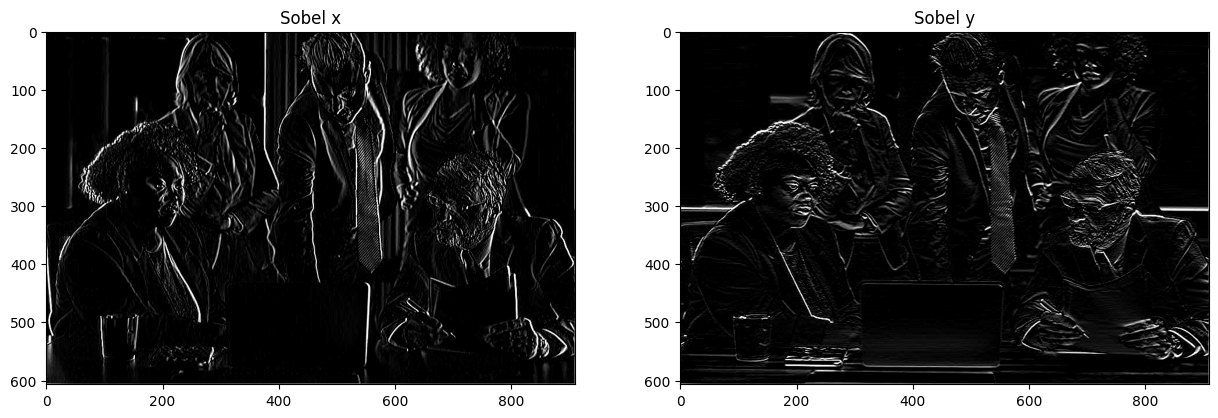

In [14]:
def apply_kernel(pil_image, kernel):
    """Apply a 3x3 NumPy kernel to a PIL Image (channel by channel)."""
    # 1. Flip columns to align NumPy's layout with PIL's spatial (x, y) indexing
    flipped_kernel = kernel[:, ::-1]

    # 2. Flatten the 2D kernel to a 1D list of integers as required by PIL's Kernel filter
    flat_coefficients = [int(v) for v in flipped_kernel.ravel()]

    # 3. Split the image into individual color bands/channels (e.g., R, G, B)
    image_channels = pil_image.split()

    # 4. Apply the kernel filter to each channel individually
    filtered_channels = []
    for channel in image_channels:
        kernel_filter = ImageFilter.Kernel((3, 3), flat_coefficients, scale=1)
        filtered_channels.append(channel.filter(kernel_filter))

    # 5. Merge the filtered channels back into a single image
    return Image.merge(pil_image.mode, filtered_channels)

# Create a custom kernel

# 3x3 array for edge detection
sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

sobel_x = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
])

# Filter the image by passing the kernel over it
filtered_people_x = apply_kernel(gray_people, sobel_x)
filtered_people_y = apply_kernel(gray_people, sobel_y)

f, (ax1,ax2) = plt.subplots(1, 2, figsize=(15,5))
ax1.set_title('Sobel x')
ax1.imshow(filtered_people_x, cmap='gray')

ax2.set_title('Sobel y')
ax2.imshow(filtered_people_y, cmap='gray')

### Understanding `ravel()`

The `.ravel()` method in NumPy is used to **flatten** a multi-dimensional array (such as a 2D kernel matrix) into a contiguous **1D (one-dimensional) array**.

#### Why is it used here?
PIL's `ImageFilter.Kernel` expects the matrix coefficients to be passed as a flat, 1D sequence of integers or floats rather than a 2D NumPy array. Using `.ravel()` allows us to quickly convert the 2D Sobel matrices into the 1D structure required by PIL.

**Example:**
```python
# 2D Array
sobel_x = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
])

# Flattened 1D Array
flat_array = sobel_x.ravel()
# Output: array([-1,  0,  1, -2,  0,  2, -1,  0,  1])
```

### Create binary images

One of the important practical aims of image processing is the demarcation of objects appearing in digital images. This process is called segmentation, and a good approximation to it can often be achieved by thresholding. Broadly, this involves separating the dark and light regions of the image, and thus identifying dark objects on a light background (or vice versa).


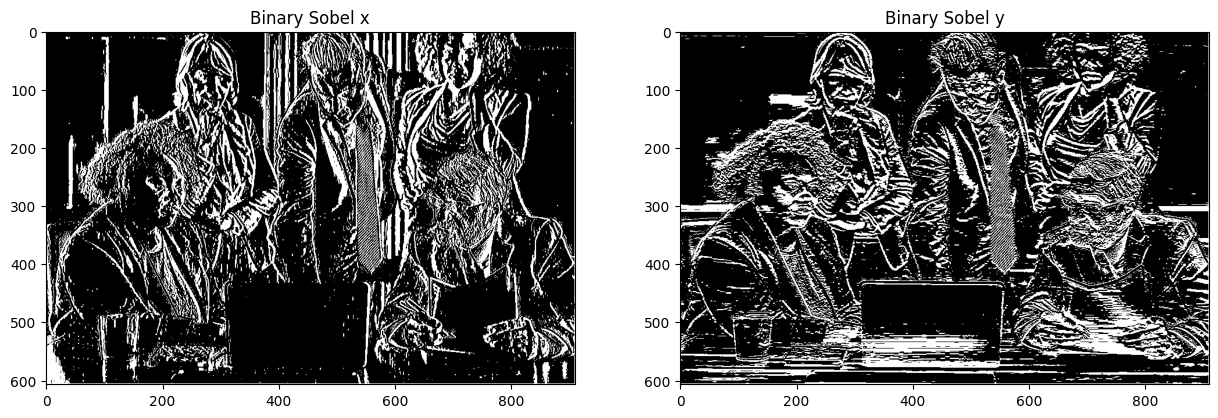

In [15]:
gray_x = np.array(filtered_people_x)
gray_y = np.array(filtered_people_y)

# The threshold value of 10 means that all pixels with values below or equal to 10 are converted into 0 (black), and all pixels with values above 10 are converted into 255 (white).
binary_image_x = ((gray_x > 10) * 255).astype(np.uint8)
binary_image_y = ((gray_y > 10) * 255).astype(np.uint8)

f2, (ax21,ax22) = plt.subplots(1, 2, figsize=(15,5))
ax21.set_title('Binary Sobel x')
ax21.imshow(binary_image_x, cmap='gray')

ax22.set_title('Binary Sobel y')
ax22.imshow(binary_image_y, cmap='gray')


## Low-pass filters

Noise in an image is generally seen as speckles or discoloration in an image, which usually does not contain useful information. It may even affect the outcome of image processing steps; high-pass filters can amplify the noise if it not removed first. Low-pass filters are used to remove this noise. They block certain high frequency content and blur or smooth the appearance of the image, reducing high frequency noise.

The simples low-pass filter is the averaging kernel:

$\frac{1}{9} \left( \begin{matrix} 1&1&1\\ 1&1&1 \\ 1&1&1 \end{matrix} \right)$

These filters typically take an average of neighboring pixels, and not a difference.

### Gaussian Blur

Unlike the averaging kernel, the Gaussian blur kernel blurs the image, while also preserving edge information, making it, perhaps, the most frequently used filter in computer vision. It is essentially a weighted average that gives the most weight to the center, while also considering the surrounding pixels.

$\frac{1}{16} \left( \begin{matrix} 1&2&1\\ 2&4&2 \\ 1&2&1 \end{matrix} \right)$

### Gaussian blur an image

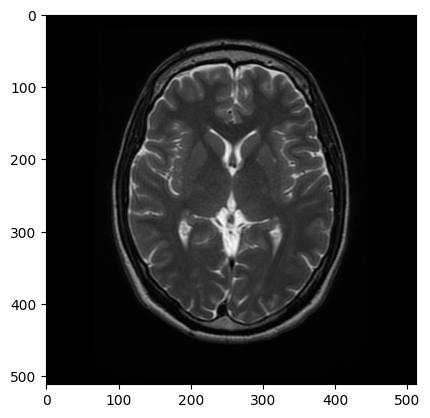

In [16]:
# blurring is often used in medical applications that have too much noise
image_brain = Image.open('DL_Data_sets/images/brain_MR.jpg')

gray_brain = image_brain.convert('L')

plt.imshow(gray_brain, cmap='gray')


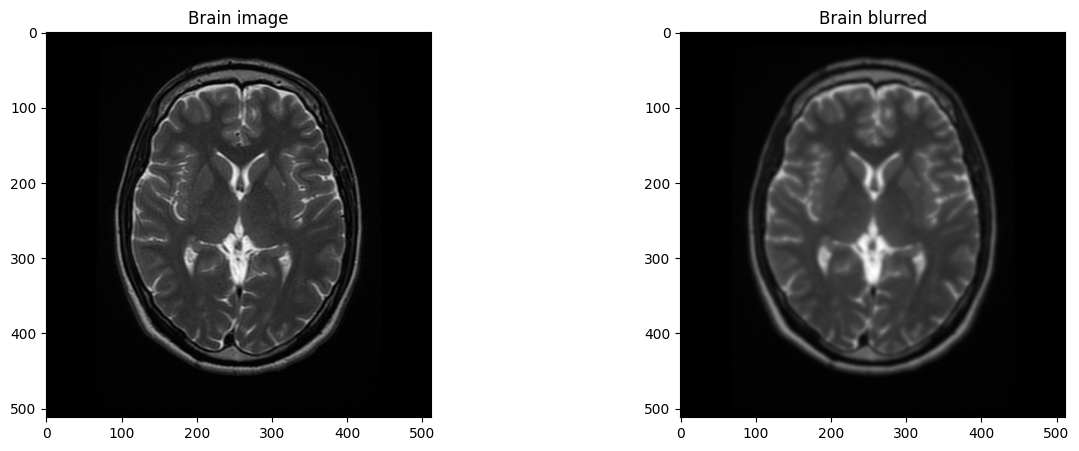

In [17]:
# take the grayscale brain image and apply a gaussian blur
# (PIL's GaussianBlur takes the radius, i.e. the standard deviation of the kernel)
gray_brain_blur = gray_brain.filter(ImageFilter.GaussianBlur(radius=2))

f3, (ax31,ax32) = plt.subplots(1, 2, figsize=(15,5))
ax31.set_title('Brain image')
ax31.imshow(gray_brain, cmap='gray')

ax32.set_title('Brain blurred')
ax32.imshow(gray_brain_blur, cmap='gray')


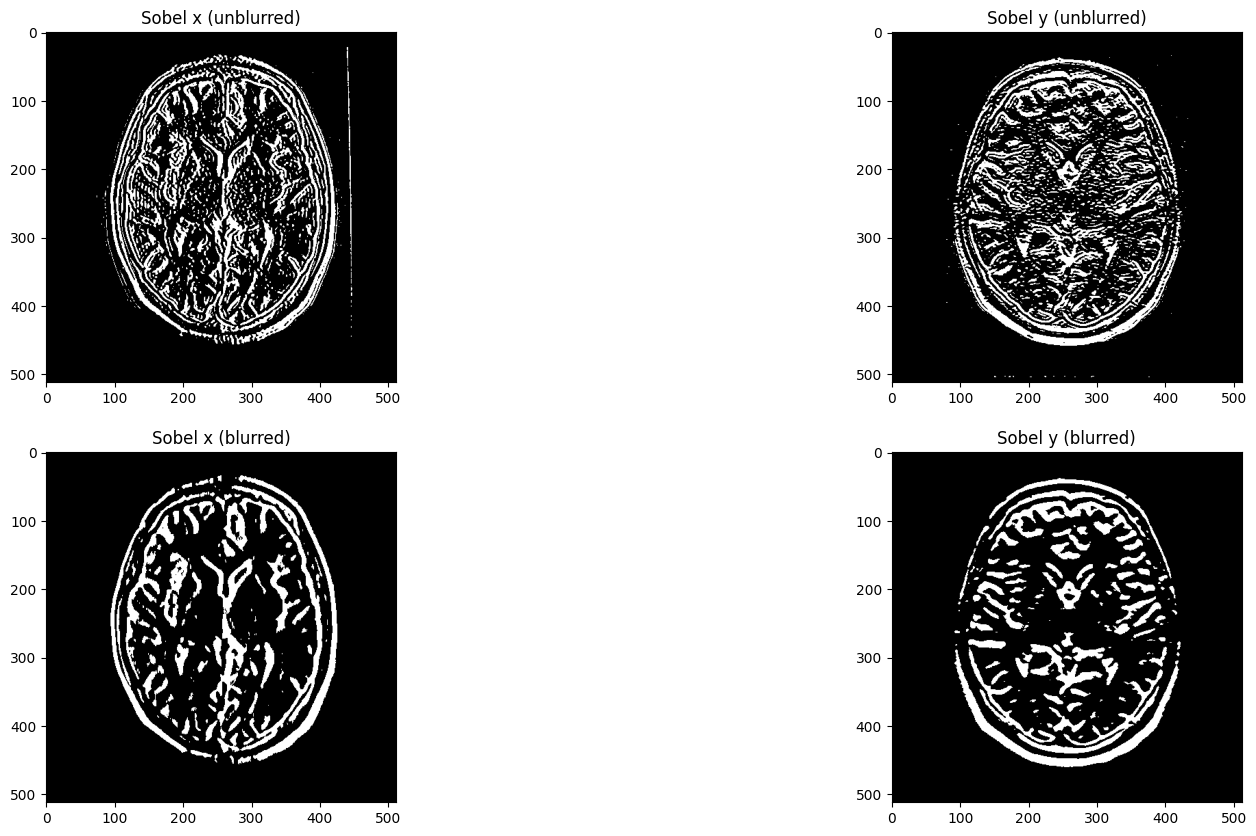

In [18]:
def to_binary(pil_image, threshold=10):
    """Binary thresholding: pixels <= threshold become 0 (black), the rest 255 (white)."""
    arr = np.array(pil_image)
    return ((arr > threshold) * 255).astype(np.uint8)

sobel_brain_x = apply_kernel(gray_brain, sobel_x)
sobel_brain_y = apply_kernel(gray_brain, sobel_y)

sobel_brain_blur_x = apply_kernel(gray_brain_blur, sobel_x)
sobel_brain_blur_y = apply_kernel(gray_brain_blur, sobel_y)

binary_brain_x = to_binary(sobel_brain_x)
binary_brain_y = to_binary(sobel_brain_y)

binary_brain_blur_y = to_binary(sobel_brain_blur_y)
binary_brain_blur_x = to_binary(sobel_brain_blur_x)

f4, ((ax41,ax42), (ax43, ax44)) = plt.subplots(2, 2, figsize=(20,10))

ax41.set_title('Sobel x (unblurred)')
ax41.imshow(binary_brain_x, cmap='gray')

ax42.set_title('Sobel y (unblurred)')
ax42.imshow(binary_brain_y, cmap='gray')

ax43.set_title('Sobel x (blurred)')
ax43.imshow(binary_brain_blur_x, cmap='gray')

ax44.set_title('Sobel y (blurred)')
ax44.imshow(binary_brain_blur_y, cmap='gray')


## Additional filters

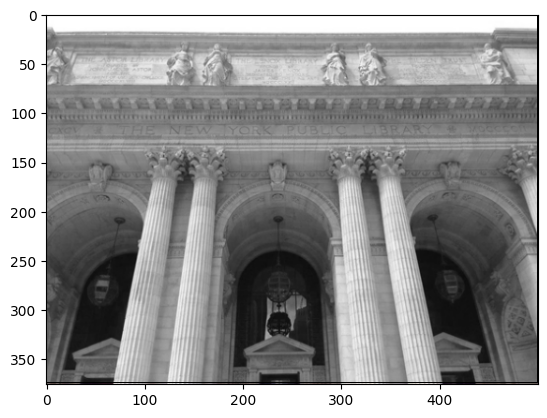

In [19]:
archway_image = Image.open('DL_Data_sets/images/archway.png').convert('RGB')  # drop the alpha channel

plt.imshow(archway_image)


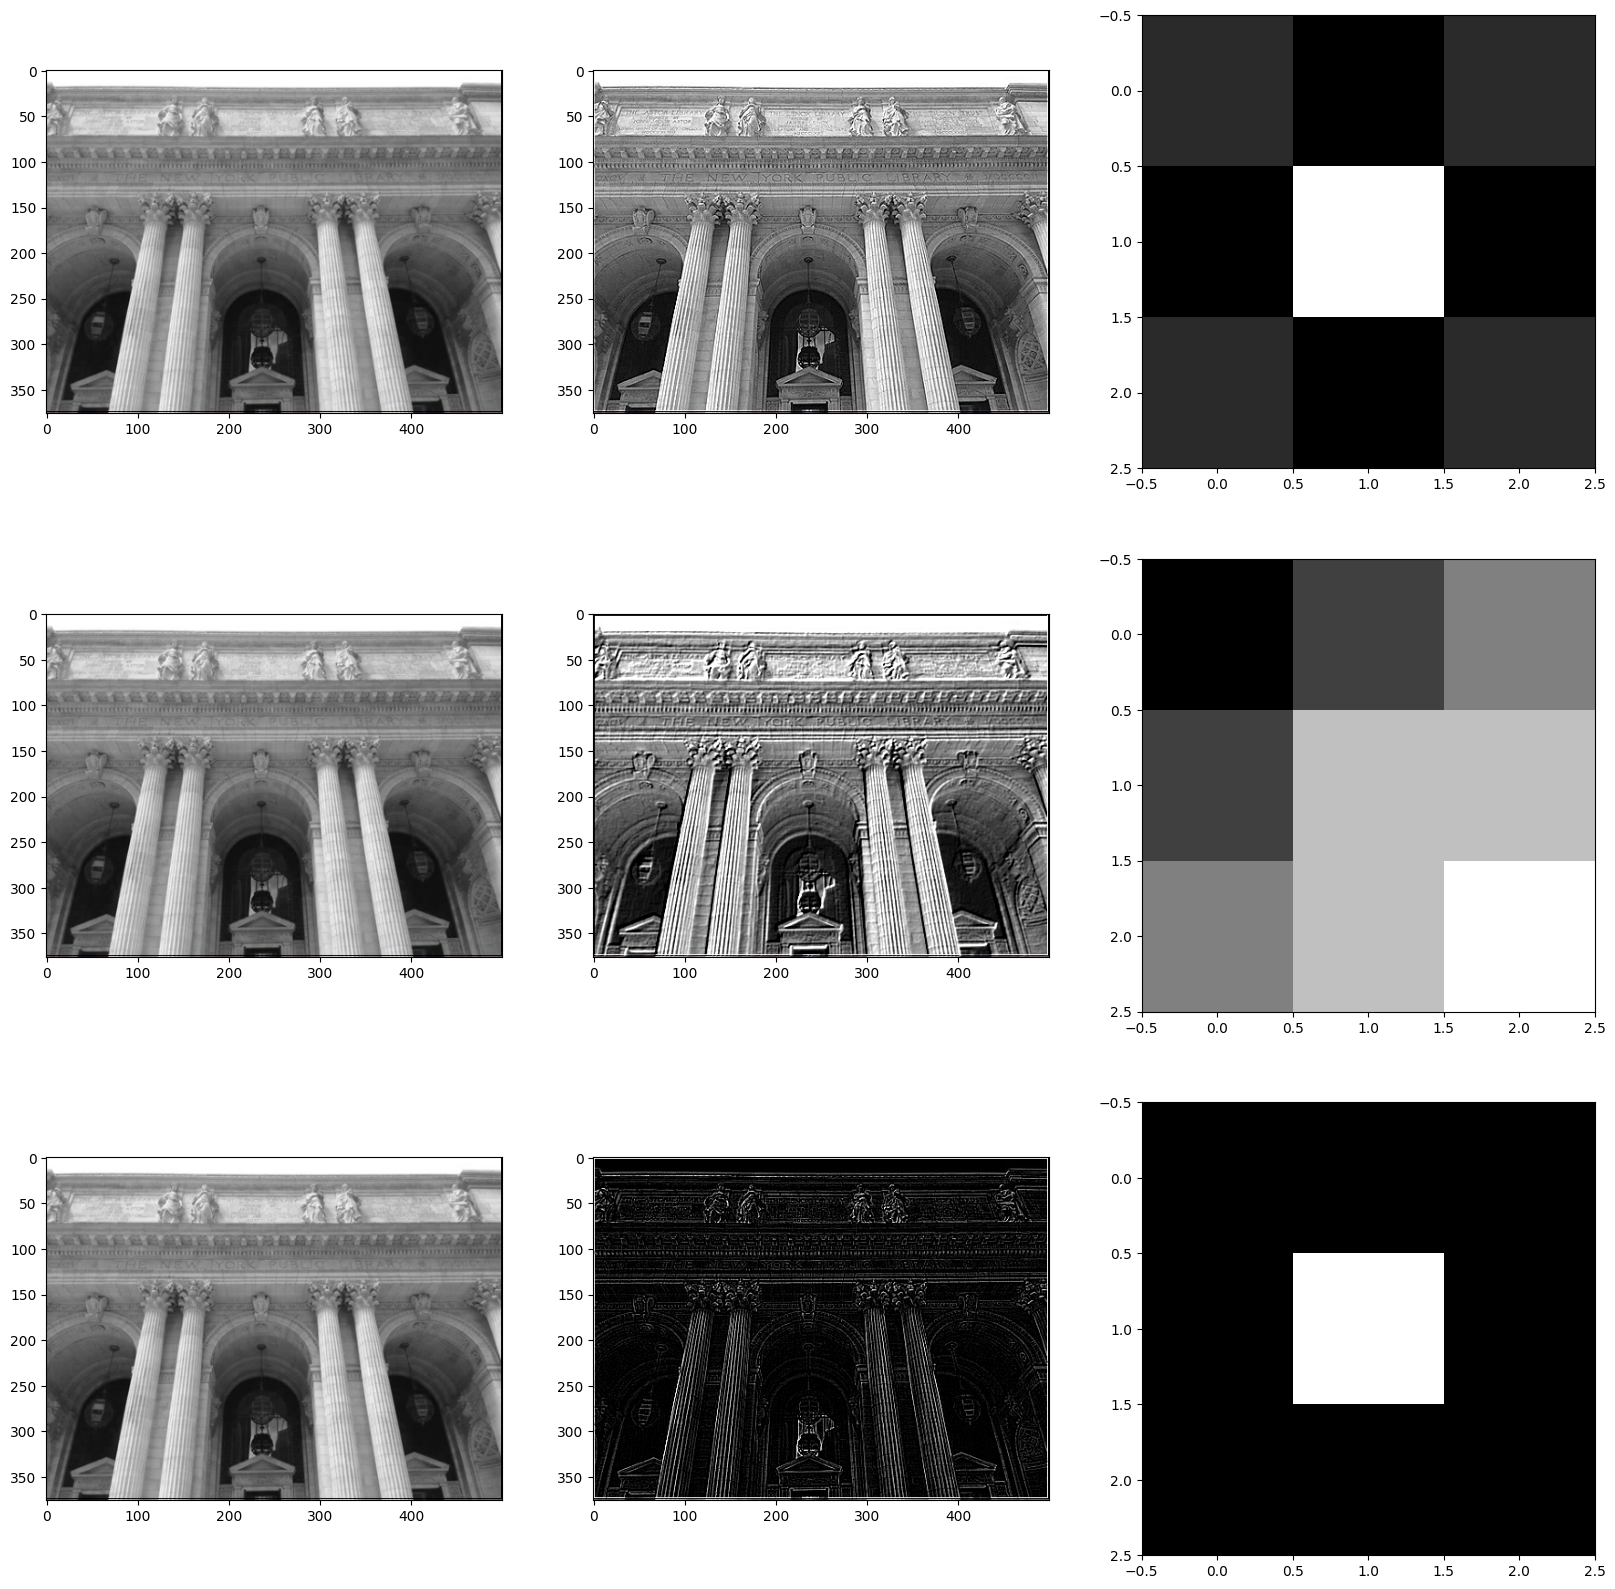

In [20]:
sharpen_filter = np.array([
   [0, -1, 0],
   [-1, 5, -1],
   [0, -1, 0]
])

emboss_filter = np.array([
    [-2, -1, 0],
    [-1, 1, 1],
    [0, 1, 2]
])

outline_filter = np.array([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1]
])

# apply_kernel handles the kernel orientation, so even the (asymmetric)
# emboss filter behaves as a true convolution, channel by channel
sharpen = apply_kernel(archway_image, sharpen_filter)
emboss = apply_kernel(archway_image, emboss_filter)
outline = apply_kernel(archway_image, outline_filter)

f, axes = plt.subplots(3, 3, figsize=(20, 20))
axes[0][0].imshow(archway_image)
axes[0][1].imshow(sharpen)
axes[0][2].imshow(sharpen_filter, cmap='gray')
axes[1][0].imshow(archway_image)
axes[1][1].imshow(emboss)
axes[1][2].imshow(emboss_filter, cmap='gray')
axes[2][0].imshow(archway_image)
axes[2][1].imshow(outline)
axes[2][2].imshow(outline_filter, cmap='gray')
